# Exploratory Data Analysis (EDA)

This is an initial exploration of the BODMAS malware dataset to understand its structure, characteristics, and potential data-quality issues before preprocessing and model development.

The exploration focuses on:
- Understanding the dataset dimensions and feature representation.
- Examining the distribution of benign and malicious samples.
- Exploring selected feature distributions.
- Investigating correlations between selected features.

The findings from this notebook will help guide the preprocessing decisions made in the next stage of the project.

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path('../../data/raw/bodmas')
FILENAME = 'bodmas.npz'
RANDOM_STATE = 42

## 1. Load the Dataset

The BODMAS dataset is provided as a NumPy archive (bodmas.npz) containing:
- X: the feature matrix, where each row represents a sample and each column represents a numerical feature extracted from a Windows Portable Executable (PE) file.
- y: the corresponding binary labels, indicating whether each sample is benign or malicious.

In [3]:
data = np.load(DATA_DIR / FILENAME)

X = data['X']
y = data['y']

print('Features shape:', X.shape)
print('Labels shape:', y.shape)
print('Data type:', X.dtype)

Features shape: (134435, 2381)
Labels shape: (134435,)
Data type: float32


## 2. Initial Dataset Inspection

First we inspect the dimensions, data types, and label values.

This allows us to understand the size of the dataset, the number of features available for classification, and how the target labels are represented.

We also verify that the feature matrix and label array contain the same number of samples.

In [4]:
df = pd.DataFrame(X)
df['label'] = y

df.head()

,0,1,2,3,4,5,6,7,8,9,...,2372,2373,2374,2375,2376,2377,2378,2379,2380,label
0,0.056742,0.008017,0.007762,0.005466,0.007762,0.004446,0.005430,0.003061,0.009475,0.006305,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,0.007062,0.004500,0.004498,0.004318,0.004410,0.004330,0.004265,0.004068,0.004391,0.004306,...,0.0,0.0,0.0,120.0,16564.0,0.0,0.0,0.0,0.0,0
2,0.020975,0.004699,0.004002,0.004419,0.004214,0.003865,0.003973,0.004297,0.003921,0.004145,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,0.006482,0.003821,0.003788,0.003866,0.003734,0.003784,0.003884,0.003937,0.003805,0.003809,...,0.0,0.0,0.0,140.0,16384.0,0.0,0.0,0.0,0.0,0
4,0.022135,0.003972,0.003834,0.003869,0.003759,0.003765,0.003777,0.003863,0.003773,0.003798,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 134435 entries, 0 to 134434
Columns: 2382 entries, 0 to label
dtypes: float32(2381), int32(1)
memory usage: 1.2 GB


In [6]:
df.describe()

,0,1,2,3,4,5,6,7,8,9,...,2372,2373,2374,2375,2376,2377,2378,2379,2380,label
count,134435.000000,1.344350e+05,1.344350e+05,134435.000000,134435.000000,134435.000000,134435.000000,134435.000000,134435.000000,134435.000000,...,1.344350e+05,1.344350e+05,1.344350e+05,1.344350e+05,1.344350e+05,1.344350e+05,1.344350e+05,1.344350e+05,1.344350e+05,134435.000000
mean,0.172645,1.010058e-02,6.500319e-03,0.005235,0.006897,0.004137,0.004883,0.003462,0.005583,0.003182,...,8.738788e+05,5.165681e+05,8.146577e+05,7.881239e+05,1.007259e+06,3.951367e+05,6.478354e+05,1.250015e+07,4.992830e+05,0.426176
std,0.190497,1.705026e-02,6.990666e-03,0.006139,0.008296,0.004133,0.005712,0.003811,0.003947,0.003274,...,3.964426e+07,3.834976e+07,4.814588e+07,5.777078e+07,4.260502e+07,3.066413e+07,3.782341e+07,1.492778e+08,3.673602e+07,0.494522
min,0.000127,4.840046e-07,2.765741e-07,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,0.018336,3.932182e-03,3.635159e-03,0.003149,0.003747,0.002589,0.002478,0.002123,0.003523,0.001717,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
50%,0.120494,6.536479e-03,4.371869e-03,0.003999,0.004731,0.003864,0.003808,0.003573,0.004339,0.003130,...,0.000000e+00,0.000000e+00,0.000000e+00,7.200000e+01,8.408000e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
75%,0.250196,1.353226e-02,7.140411e-03,0.006340,0.008649,0.004910,0.005038,0.003977,0.007394,0.003904,...,0.000000e+00,0.000000e+00,0.000000e+00,5.880000e+02,1.288340e+05,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
max,0.999983,9.880831e-01,3.207031e-01,0.343288,0.362614,0.408537,0.314893,0.679162,0.123530,0.329137,...,3.590280e+09,3.758097e+09,3.347698e+09,4.283486e+09,3.914422e+09,3.771926e+09,3.823243e+09,3.758097e+09,2.906326e+09,1.000000


## 3. Class Distribution

We examine the number and proportion of benign and malicious samples in the dataset.

This step is important because an imbalanced dataset can influence model performance.

Understanding the class distribution helps us decide whether additional measures may be needed during model training and evaluation.

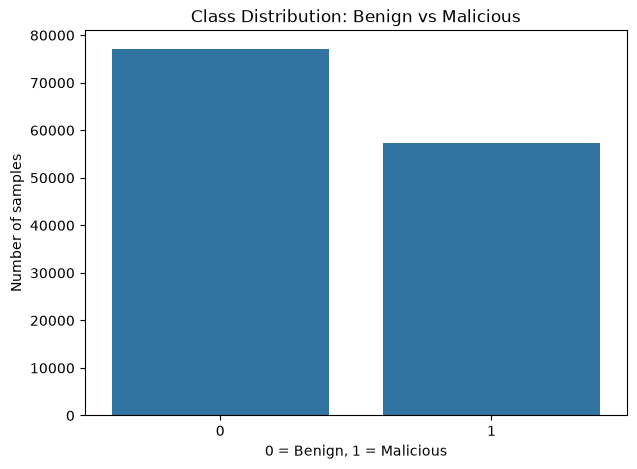

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(x=df['label'])

plt.title('Class Distribution: Benign vs Malicious')
plt.xlabel('0 = Benign, 1 = Malicious')
plt.ylabel('Number of samples')

plt.show()

## 4. Feature Distribution Analysis

We visualize the distributions of selected features to better understand their numerical ranges and patterns.

Since BODMAS contains a high-dimensional feature matrix, examining every feature individually would be impractical. We therefore select a limited number of features for an initial visual inspection.

These plots can help reveal skewed distributions, unusual values, and differences in feature behavior across samples.

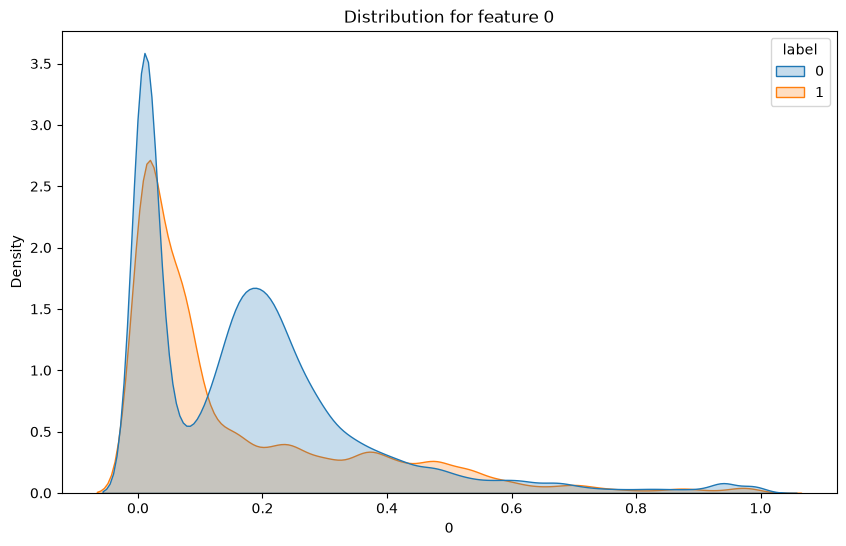

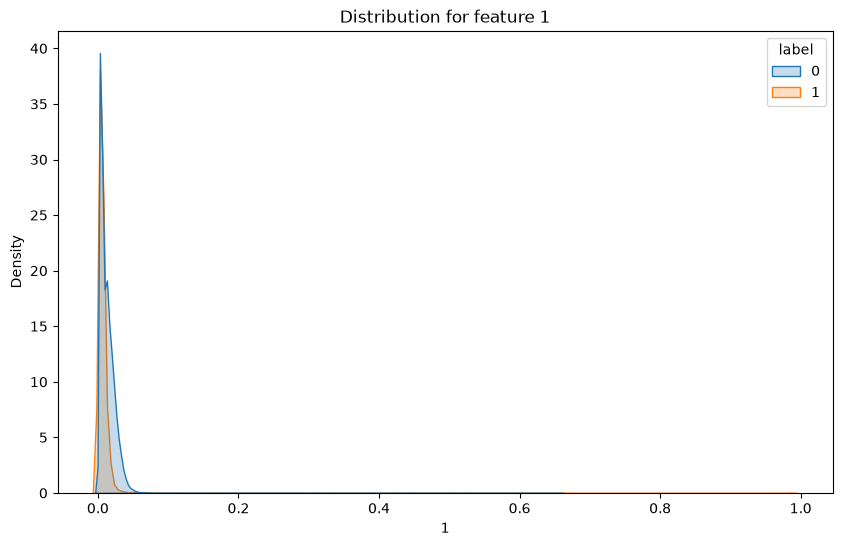

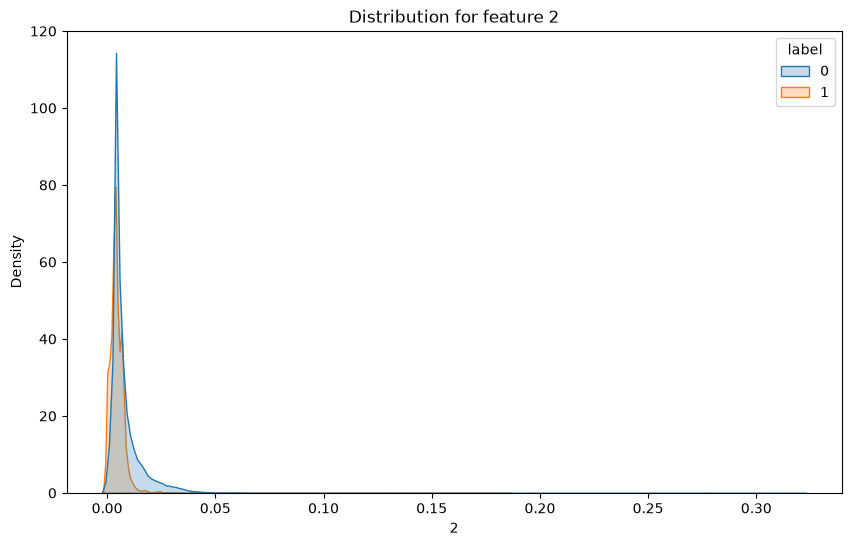

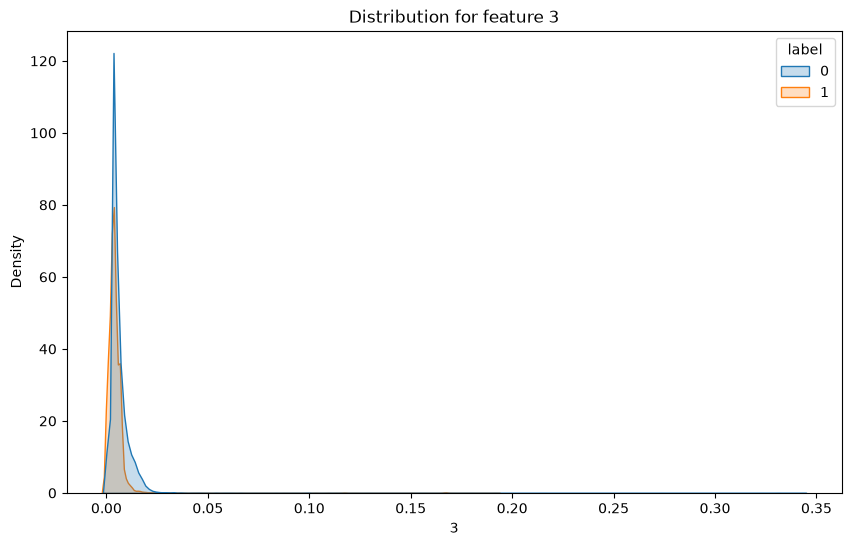

In [17]:
for i in range(4):
    plt.figure(figsize=(10, 6))
    sns.kdeplot(x=df[i], hue=df['label'], fill=True)
    plt.title(f'Distribution for feature {i}')
    plt.show()

## 5. Feature Correlation Analysis

We calculate and visualize the correlations between a selected subset of features.

Correlation analysis helps identify features that may contain similar or redundant information. Highly correlated features may influence model complexity and interpretation.

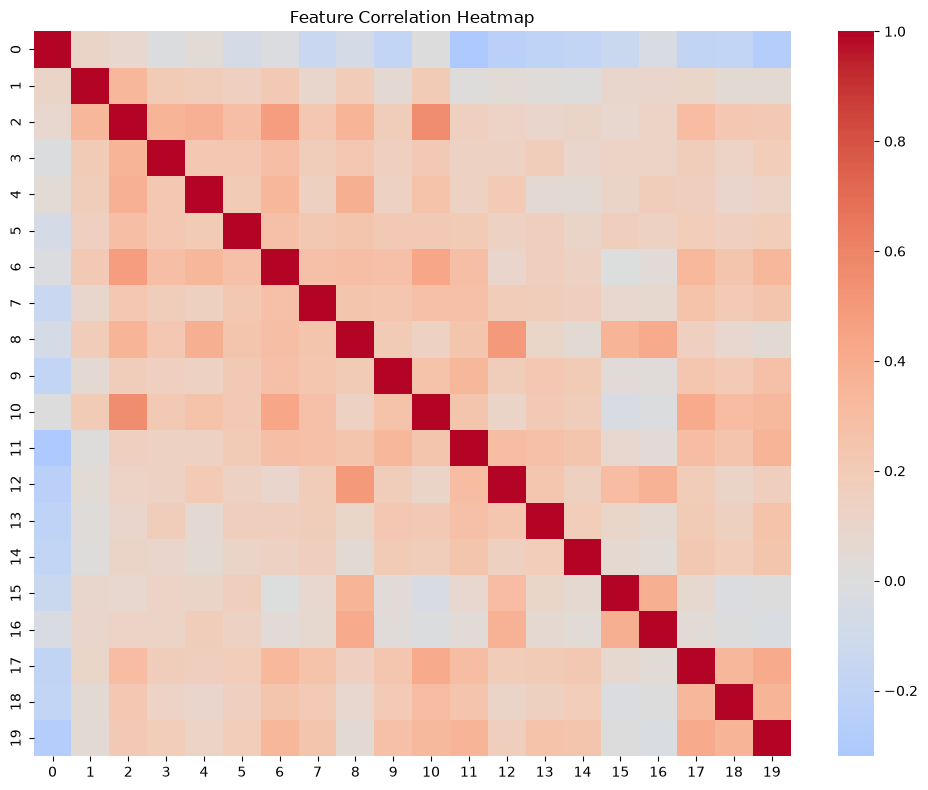

In [21]:
correlation = df[range(20)].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0,
    annot=False
)

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

## 6. Exploration Summary

This notebook provided an initial understanding of the BODMAS dataset, including its structure, class distribution, feature characteristics, and potential data-quality issues.

The observations from this stage will guide the preprocessing workflow. In particular, we will determine how to handle any invalid values, prepare consistent training and evaluation splits, and apply feature scaling where appropriate.